# 03 - The model parts and how well each one works

To check each part honestly, this notebook fits on **February to June** and checks on **July** (not used for fitting).

| Part | What it does |
|---|---|
| (A) Fair value | Black-Scholes price with a volatility forecast (HAR model) for the protection duration |
| (B) Anchor | Jasper's base price; where it is missing, a model rebuilds it from (A) and market features |
| (C) Risk multiplier | expected payout = anchor x multiplier, learned from real payouts |
| (D) Reference price | the price customers pay today, as a factor on the anchor (no outcomes used) |
| Pricing rule | premium = expected payout + reference price / k  (k = 3), within caps |

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

In [2]:
from pricing.data import load_orders, load_btc
from pricing.features import market_features
from pricing.pipeline import HybridPricer, Config
from pricing.evaluate import calibration_table

train = load_orders("train"); btc = load_btc(); mkt = market_features(btc)
X = pd.read_parquet(OUT / "features_train.parquet").join(pd.read_parquet(OUT / "external_train.parquet"))
cut = pd.Timestamp("2026-07-01")
fit_rows = train[(train.created < cut) & train.has_outcome & (train.expiry <= cut)]
chk_rows = train[(train.created >= cut) & train.has_outcome]
EVENTS = ("event_in_window", "hours_to_event", "hours_since_event")
pricer = HybridPricer(Config(risk_features=EVENTS)).fit(fit_rows, X.loc[fit_rows.index], btc, mkt, cutoff=cut)
out = pricer.predict(chk_rows, X.loc[chk_rows.index])
print(f"fitted on {len(fit_rows):,} orders, checked on {len(chk_rows):,} July orders")

fitted on 4,576 orders, checked on 2,571 July orders


## (A) Volatility forecast: forecast vs realized volatility over each order's duration (July)

In [3]:
import numpy as np
r2 = np.log(btc["close"]).diff().pow(2).fillna(0).cumsum()
start = X.loc[chk_rows.index, "info_minute"]
h = chk_rows["duration_s"] // 60
end = start + pd.to_timedelta(h, unit="min")
realized = np.sqrt((r2.reindex(end).to_numpy() - r2.reindex(start).to_numpy()) * 525600 / h.to_numpy())
f = pd.DataFrame({"forecast": out["sigma_forecast"], "realized": realized, "duration_h": chk_rows["duration_s"] / 3600}).dropna()
print("correlation of log forecast and log realized volatility:", round(np.corrcoef(np.log(f.forecast), np.log(f.realized))[0, 1], 2))
f.groupby("duration_h")[["forecast", "realized"]].median().round(3)

correlation of log forecast and log realized volatility: 0.53


,forecast,realized
duration_h,,
0.500,0.410,0.411
1.000,0.354,0.363
2.000,0.348,0.378
4.000,0.346,0.420
8.000,0.357,0.341
12.000,0.362,0.311
24.000,0.358,0.288


## (B) Base price rebuild: error on July orders that have a real base price

median absolute error: 9.2%   90% of errors within: 25.9%


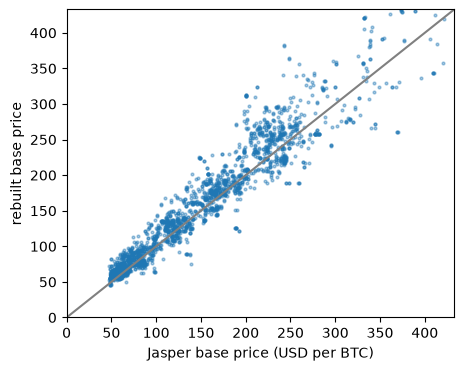

In [4]:
has = chk_rows["base"].notna()
err = out.loc[has, "base_rebuilt_per_BTC"] / chk_rows.loc[has, "base"] - 1
print(f"median absolute error: {err.abs().median():.1%}   90% of errors within: {err.abs().quantile(0.9):.1%}")
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(chk_rows.loc[has, "base"], out.loc[has, "base_rebuilt_per_BTC"], s=4, alpha=0.4)
lim = [0, chk_rows.loc[has, "base"].quantile(0.99)]
ax.plot(lim, lim, color="grey"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Jasper base price (USD per BTC)"); ax.set_ylabel("rebuilt base price"); plt.show()

## (C) Risk multiplier

Factors of the selected risk model (constant plus the economic-calendar block; notebook 04 explains the choice).
A factor above 1 increases the expected payout.

In [5]:
print("calibration constant (payout / anchor, dollar-weighted):", round(pricer.risk.const, 3))
pricer.risk.factors().round(3).to_frame("factor per unit")

calibration constant (payout / anchor, dollar-weighted): 1.284


,factor per unit
event_in_window,1.191
hours_to_event,0.999
hours_since_event,1.000


In [6]:
cal = calibration_table(out["expected_payout_per_BTC"], chk_rows["post_payout"], chk_rows["qty"], bins=5)
cal.round(2)

,orders,predicted_usd,real_usd,real/predicted
bin,,,,
0,515.000,"1,759.460","2,121.310",1.210
1,514.000,"13,179.180","16,567.300",1.260
2,514.000,"18,073.570","23,990.280",1.330
3,514.000,"28,213.130","27,929.190",0.990
4,514.000,"30,718.270","32,826.200",1.070


## (D) Reference price: predicted vs Jasper's real price (July)

In [7]:
e = np.log(out["reference_price_per_BTC"] / chk_rows["paid"])
print(f"median absolute error: {np.expm1(e.abs().median()):.1%}")
print("constant markup instead of the model:", round(pricer.ref.const, 3), "x anchor")

median absolute error: 22.9%
constant markup instead of the model: 1.546 x anchor


## The pricing rule on July orders

premium vs Jasper's real price: median 1.07x, lower for 40% of orders, above 1.5x for 2%


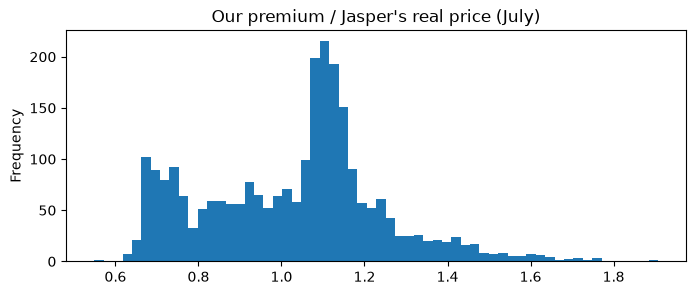

In [8]:
ratio = out["premium_per_BTC"] / chk_rows["paid"]
print(f"premium vs Jasper's real price: median {ratio.median():.2f}x, lower for {np.mean(ratio < 1):.0%} of orders, above 1.5x for {np.mean(ratio > 1.5):.0%}")
ratio.clip(0, 3).plot.hist(bins=60, figsize=(8, 3), title="Our premium / Jasper's real price (July)"); plt.show()